## Assignment #6

In [19]:
from grader_shared import SubmissionWidget
SubmissionWidget()


In [20]:
# Set random seed and ensure plots are displayed in the notebook
import numpy as np
import arviz as az
rnd_seed = 5
np.random.seed(rnd_seed)
%matplotlib inline

%config Inline.figure_format = 'retina'
az.rcParams["stats.hdi_prob"] = 0.89  # sets default credible interval used by arviz

In [21]:
def standardize(series):
    """Standardize a pandas series"""
    return (series - series.mean()) / series.std()

**Question 1**. In 2014, a paper was published that was entitled “Female hurricanes are deadlier than male hurricanes.” As the title suggests, the paper claimed that hurricanes with female names have caused greater loss of life, and the explanation given is that people unconsciously rate female hurricanes as less dangerous and so are less likely to evacuate. Statisticians severely criticized the paper after publication.

Here, you’ll explore the complete data used in the paper and consider the hypothesis that hurricanes with female names are deadlier.

Load the data as follows:

`df = pd.read_csv("Data/hurricanes.csv")`


The columns have the following meaning:
```
*Description*
Data used in Jung et al 2014 analysis of effect of gender of name on hurricane fatalities. Note that hurricanes Katrina (2005) and Audrey (1957) were removed from the data.

name : Given name of hurricane

year : Year of hurricane

deaths : Number of deaths

category : Severity code for storm

min_pressure : Minimum pressure, a measure of storm strength; low is stronger

damage_norm : Normalized estimate of damage in dollars

female : Indicator variable for name categorized as "female"

femininity : 1-11 scale from totally masculine (1) to totally feminine (11) for name. Average of 9 scores from 9 raters.

*Reference* 
Jung et al. 2014. Female hurricanes are deadlier than male hurricanes. PNAS.
```

To begin, you will focus on constructing Poisson Generalized Linear Models to investigate the relationship between name femininity and hurricane deaths. In pursuing this goal, you will fit two different statistical models. One will be an intercept-only model of the expected number of deaths from a hurricane using an intercept term with no predictors in the model. The second will include an intercept and a storm's femininity score as a predictor to define the expected number of deaths.

**Begin by justifying the priors that you will use for the prior predictive simulations in your models. This requires providing justifications for two parameters: an intercept parameter and a slope parameter for the (standardized) femininity score.** 

1. Perform a brief web search on the expected number deaths due to hurricanes to help choose reasonable priors for your model. 
1. Include a brief statement (**limited to no more than 3-4 sentences**) on the information obtained and the source(s) used based on your web search.

**⚠️ PLEASE DO NOT DELETE THIS CELL**

Rappaport (2014) reports that hurricane fatalities vary widely, with some storms causing relatively few deaths and a small number causing many more. I used an intercept prior of Normal(log(10), 1), centered on about 10 expected deaths but allowing substantial variation. For the standardized femininity coefficient, I used Normal(0, 0.5) to avoid assuming the direction of the relationship while allowing meaningful effects.

**Sources:** [Rappaport (2014)](https://journals.ametsoc.org/doi/pdf/10.1175/BAMS-D-12-00074.1); [NOAA Hurricane FAQ](https://www.aoml.noaa.gov/hrd/tcfaq/E12.html?print=yes).


3. **Perform a prior predictive simulations** for the intercept-only model.
    * Refer to the Poisson GLM lecture (slides titled "Poisson Priors") for examples of prior predictive simulations.
    * For this model, a good way to analyze the prior for the intercept parameter is to visualize the distribution of prior samples using a histogram or kde plot.

/opt/conda/envs/fnds/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


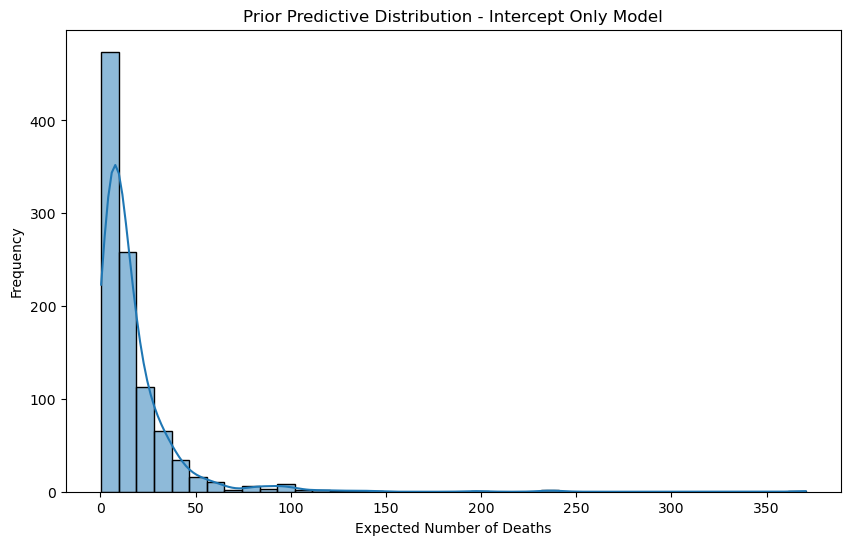

In [22]:

# import libraries
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Generate at least 100 samples from a Normal distribution
q1_2_num_samples = 1000
q1_2_alpha = np.random.normal(
    loc=np.log(10),
    scale=1,
    size=q1_2_num_samples
)

# Calculate the exponential of every value in q1_2_alpha
q1_2_lam = np.exp(q1_2_alpha)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the prior distribution of expected deaths
sns.histplot(q1_2_lam, bins=40, kde=True, ax=ax)

ax.set_xlabel("Expected Number of Deaths")
ax.set_ylabel("Frequency")
ax.set_title("Prior Predictive Distribution - Intercept Only Model")

# Store the Axes object for the autograder
q1_2_plot = ax

plt.show()


4. **Perform a prior predictive simulation** for the model that includes femininity score as a predictor.
    1. Refer to the Poisson GLM lecture (slides titled "Poisson Priors") for examples of prior predictive simulations.
    2. For this model, you prior predictive simulation will include a plot of femininity vs expected number of deaths that shows how the expected number of deaths change as the (standardized) femininity score changes.

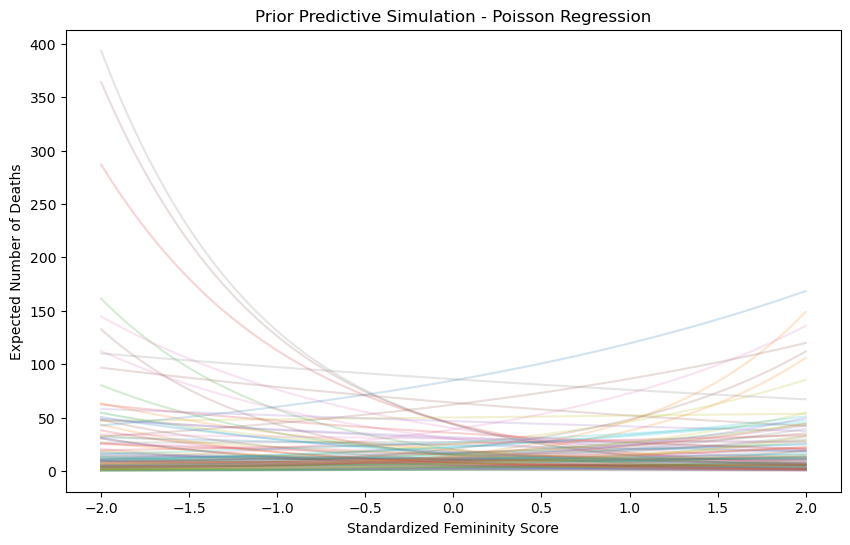

In [23]:

import numpy as np
import matplotlib.pyplot as plt

# Define the number of prior samples to generate (at least 100)
q1_3_num_samples = 1000

# Define standardized femininity scores
q1_3_fem_seq = np.linspace(-2, 2, 100)

# Sample from the prior for the intercept
q1_3_alpha = np.random.normal(
    loc=np.log(10),
    scale=1,
    size=q1_3_num_samples
)

# Sample from the prior for the slope
q1_3_beta = np.random.normal(
    loc=0,
    scale=0.5,
    size=q1_3_num_samples
)

# Create the plot object
fig, ax = plt.subplots(figsize=(10, 6))

# Define the number of regression lines to generate
q1_3_num_lines = 100

# Plot prior predictive regression lines
for i in range(q1_3_num_lines):
    lam = np.exp(
        q1_3_alpha[i] + q1_3_beta[i] * q1_3_fem_seq
    )
    ax.plot(q1_3_fem_seq, lam, alpha=0.2)

ax.set_xlabel("Standardized Femininity Score")
ax.set_ylabel("Expected Number of Deaths")
ax.set_title("Prior Predictive Simulation - Poisson Regression")

# Store the Axes object for the autograder
q1_3_plot = ax

plt.show()


Approximate the posterior of a Poisson model of hurricane deaths using *femininity* (**after standardization**) as a predictor. This **model will include two parameters**: an **intercept** and a **coefficient** that measures the effect of femininity on the expected number of deaths. **Be sure to calculate the log-likelihood when sampling from your posterior to evaluate the predictive ability of this model**.

In [ ]:


import pymc as pm
import pandas as pd
import numpy as np

# Read in data from Data/hurricanes.csv
q1_df = pd.read_csv("Data/hurricanes.csv")

# Assign femininity values from dataset
q1_femininity = q1_df["femininity"].values

# Standardize femininity scores
q1_fem_std = (
    q1_femininity - np.mean(q1_femininity)
) / np.std(q1_femininity)

# Assign death counts from the dataset
q1_deaths = q1_df["deaths"].values

# Define the model and run the approximation
with pm.Model() as q1_4_model:

    # Mutable data for posterior predictive checks
    if hasattr(pm, "MutableData"):
        fem_data = pm.MutableData("fem_std", q1_fem_std)
    else:
        fem_data = pm.Data("fem_std", q1_fem_std)

    # Prior for intercept
    alpha = pm.Normal("alpha", mu=np.log(10), sigma=1)

    # Prior for slope
    beta = pm.Normal("beta", mu=0, sigma=0.5)

    # Expected number of deaths
    lam = pm.Deterministic(
        "lam",
        pm.math.exp(alpha + beta * fem_data)
    )

    # Poisson likelihood
    deaths = pm.Poisson(
        "deaths",
        mu=lam,
        observed=q1_deaths,
        shape=fem_data.shape
    )

    # Estimate posterior using HMC (NUTS)
    q1_4_idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        idata_kwargs={"log_likelihood": True}
    )


Approximate the posterior of a Poisson model of hurricane deaths defining the expected number of deaths using just an intercept term. This model will include only one parameter to estimate. **Be sure to calculate the log-likelihood when sampling from your posterior to evaluate the predictive ability of this model**.

In [ ]:

# Define the model and run the approximation
with pm.Model() as q1_5_model:

    # Prior for intercept
    alpha = pm.Normal("alpha", mu=np.log(10), sigma=1)

    # Expected number of deaths
    lam = pm.Deterministic("lam", pm.math.exp(alpha))

    # Poisson likelihood
    deaths = pm.Poisson(
        "deaths",
        mu=lam,
        observed=q1_deaths
    )

    # Estimate posterior using Hamiltonian Monte Carlo MCMC
    q1_5_idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        idata_kwargs={"log_likelihood": True}
    )

    

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha]


<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:01&lt;00:00... Sampling chain 0, 0 divergences]</div>

<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:00&lt;00:00... Sampling chain 1, 0 divergences]</div>

<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:01&lt;00:00... Sampling chain 2, 0 divergences]</div>

<div><progress max="2000" value="2000"></progress> 100.00% [2000/2000 00:01&lt;00:00... Sampling chain 3, 0 divergences]</div>

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.


Generate a summary table for each model.

In [ ]:

# Create a summary table for q1_4_idata
q1_4_summary = az.summary(
    q1_4_idata,
    var_names=["alpha", "beta", "lam"],
    round_to=2
)

q1_4_summary


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,3.00,0.02,2.96,3.04,0.00,0.00,3285.56,2618.75,1.0
beta,0.24,0.03,0.20,0.28,0.00,0.00,2907.36,2117.77,1.0
lam[0],20.10,0.48,19.33,20.83,0.01,0.01,3284.17,2618.75,1.0
lam[1],13.53,0.72,12.32,14.62,0.01,0.01,2665.06,2280.11,1.0
lam[2],16.19,0.60,15.18,17.10,0.01,0.01,2679.50,2124.22,1.0
...,...,...,...,...,...,...,...,...,...
lam[87],13.86,0.71,12.66,14.92,0.01,0.01,2661.92,2280.54,1.0
lam[88],14.03,0.70,12.85,15.08,0.01,0.01,2661.05,2313.57,1.0
lam[89],24.17,0.66,23.09,25.17,0.01,0.01,4140.70,2660.49,1.0
lam[90],14.09,0.70,12.90,15.12,0.01,0.01,2660.31,2313.57,1.0


In [ ]:

# Create a summary table for q1_5_idata
q1_5_summary = az.summary(
    q1_5_idata,
    var_names=["alpha", "lam"],
    round_to=2
)

q1_5_summary


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,3.03,0.02,2.99,3.06,0.00,0.00,1427.59,2194.03,1.0
lam,20.64,0.46,19.90,21.36,0.01,0.01,1427.59,2194.03,1.0


Based on the model estimates from the last question, how strong is the association between femininity of storm name and deaths? **Limit your response to no more than 3 sentences.**

*Hint: The response to this question should be based on parameter estimate(s) from your model.* **Be sure to reference the estimated association from the tables in your answer. Be sure to comment on the uncertainty of the estimate.**

**⚠️ PLEASE DO NOT DELETE THIS CELL**

The model shows a positive association between storm-name femininity and hurricane deaths, with an estimated coefficient of β = 0.24, suggesting about 27% more expected deaths for a one-standard-deviation increase in femininity. The 89% credible interval ranges from 0.20 to 0.28, which does not include zero. This suggests strong evidence of a positive association with relatively little uncertainty, although it does not necessarily mean femininity causes more deaths.

**Question 2**. In this problem, you’ll focus on predicting deaths using the femininity score of each hurricane’s name. Use the function `pymc.sample_posterior_predictive()` to make predictions from the feminity score model to make predictions.

Use samples from the posterior distribution (stored in `q1_4_idata`) to perform your counterfactual simulation. First, define a sequence of femininity scores (on a standardized scale) and implement the counterfactual simulation. 

In [ ]:

# Define the grid of at least 30 points for standardized femininity scores
q2_fs_grid = np.linspace(
    -2,
     2,
    50
)

with q1_4_model:

    # Update the mutable data container
    pm.set_data({"fem_std": q2_fs_grid})

    # Sample posterior predictions for expected and observed deaths
    post_pred_fs_idata = pm.sample_posterior_predictive(
        q1_4_idata,
        var_names=["lam", "deaths"],
        random_seed=42
    )

    # Extract posterior predictive samples
    counter_fact_fs = az.extract(
        post_pred_fs_idata,
        group="posterior_predictive"
    )


Sampling: [deaths]


<div><progress max="4000" value="5"></progress> 0.12% [5/4000 00:00&lt;00:09]</div>

Perform posterior predictive checks to evaluate how well the femininity score model predicts the observed data. **Use posterior predictive samples from the counterfactual simulation for all plot components**. This posterior predictive check will include a plot with the following components: 

* name femininity (standardized) on the x-axis
* number of deaths on the y-axis
* observed death counts from the dataset as scatter plot points
* posterior mean showing the average relationship between femininity and number of deaths
* uncertainty of posterior mean
* uncertainty of posterior predictions
* labels for each plot component
	* add `fill_kwargs={"label": "YOUR LABEL"}` to your `arviz.hdi_plot()` calls to add a label

/opt/conda/envs/fnds/lib/python3.11/site-packages/arviz/plots/hdiplot.py:160: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi_data = hdi(y, hdi_prob=hdi_prob, circular=circular, multimodal=False, **hdi_kwargs)
/opt/conda/envs/fnds/lib/python3.11/site-packages/arviz/plots/hdiplot.py:160: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi_data = hdi(y, hdi_prob=hdi_prob, circular=circular, multimodal=False, **hdi_kwargs)


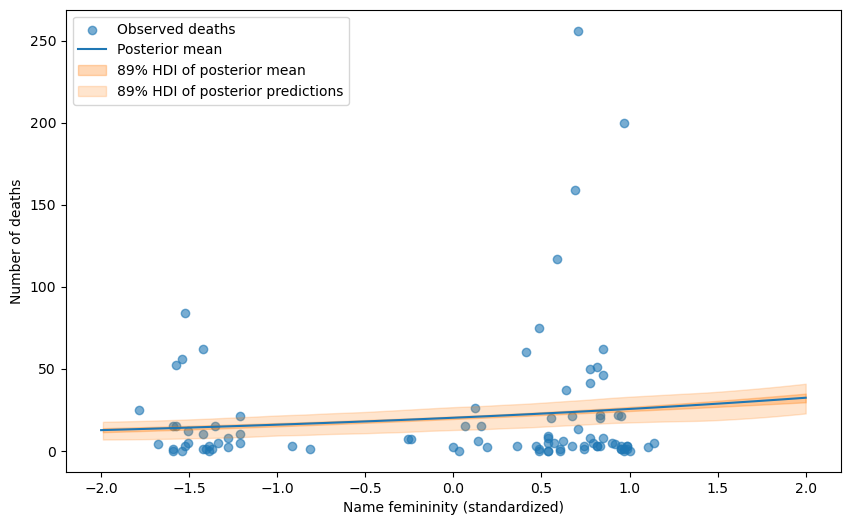

In [ ]:

import numpy as np
import arviz as az
import matplotlib.pyplot as plt

# Create the plot object
fig, ax = plt.subplots(figsize=(10, 6))

# Add observed death counts from the dataset
ax.scatter(
    q1_fem_std,
    q1_deaths,
    alpha=0.6,
    label="Observed deaths"
)

# Extract posterior predictive samples
lam_samples = counter_fact_fs["lam"].values
deaths_samples = counter_fact_fs["deaths"].values

# Add posterior mean
ax.plot(
    q2_fs_grid,
    lam_samples.mean(axis=1),
    label="Posterior mean"
)

# Add 89% HDI of posterior mean
az.plot_hdi(
    q2_fs_grid,
    lam_samples.T,
    hdi_prob=0.89,
    ax=ax,
    fill_kwargs={
        "alpha": 0.3,
        "label": "89% HDI of posterior mean"
    }
)

# Add 89% HDI of posterior predictions
az.plot_hdi(
    q2_fs_grid,
    deaths_samples.T,
    hdi_prob=0.89,
    ax=ax,
    fill_kwargs={
        "alpha": 0.2,
        "label": "89% HDI of posterior predictions"
    }
)

# Add legend
ax.legend()

# Add axes labels
ax.set_xlabel("Name femininity (standardized)")
ax.set_ylabel("Number of deaths")

# Store the Axes object for the autograder
q2_2_plot = ax

plt.show()


Based on your plot, how effective is the femininity score model at predicting storm deaths? **Limit your response to no more than 3 sentences**

**⚠️ PLEASE DO NOT DELETE THIS CELL**
The femininity score model shows a positive association with hurricane deaths, but its predictions are not very accurate. The large variation in deaths suggests that femininity alone is not a strong predictor.

**Compare the predictive ability** of the hurricane name femininity model to the intercept-only model based on the predictive criteria tools (PSIS or WAIC) covered earlier in the semester. Ensure that the comparison is reported on the **deviance** scale.

In [ ]:


# Store the InferenceData objects in q2_model_dict
q2_model_dict = {
    "femininity": q1_4_idata,
    "intercept_only": q1_5_idata
}


In [ ]:

# Compare models and store results in q2_compare_df
q2_compare_df = az.compare(
    q2_model_dict,
    ic="loo",
    scale="deviance"
)

q2_compare_df


/opt/conda/envs/fnds/lib/python3.11/site-packages/arviz/stats/stats.py:803: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/opt/conda/envs/fnds/lib/python3.11/site-packages/arviz/stats/stats.py:803: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.7 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/opt/conda/envs/fnds/lib/python3.11/site-packages/arviz/stats/stats.

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
femininity,0,4395.258202,122.497862,0.000000,0.46857,986.281224,0.000000,True,deviance
intercept_only,1,4424.175208,66.657593,28.917005,0.53143,1061.178837,140.878839,True,deviance


**State which model is better for prediction** in the markdown cell below. Please type the better model's name used in your `q2_model_dict`.

**⚠️ PLEASE DO NOT DELETE THIS CELL**

femininity

Explain what evidence leads you to this conclusion. **Limit your response to no more than 3 sentences.**

**⚠️ PLEASE DO NOT DELETE THIS CELL**

The femininity model ranks first because its PSIS-LOO deviance is lower (4395.26 vs. 4424.18). However, the difference (28.92) is small compared with its standard error (140.88), and both models have PSIS warnings, so the predictive advantage is uncertain.
